# E-Commerce Customer Behaviour Analysis
Purchase patterns, revenue drivers and customer types in a year of real retail transactions

Tools: Python · Pandas · Matplotlib · Seaborn · SciPy

Dataset: UCI Online Retail (via Kaggle). A UK-based online retailer, December 2010 to December 2011.

Author: Siddharth Suman

> **Update, October 2026.** The first version of this notebook compared registered and guest customers per *line item* and said registered customers spend 69% more. When I redid the comparison per *order*, the result went the other way. Section 4 shows both versions and what I think is going on. I also fixed the "average order value" figures in section 2, which were really averages per line item.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# I ran this in Google Colab with the CSV in my Drive.
# On your own machine: download the Kaggle file (link in the README)
# and put it in a folder called data/ next to this notebook.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/Colab Notebooks/E-commerce_data.csv'
except ImportError:
    DATA_PATH = 'data/E-commerce_data.csv'

os.makedirs('images', exist_ok=True)

df = pd.read_csv(DATA_PATH, encoding='ISO-8859-1', dtype={'InvoiceNo': str, 'StockCode': str})

print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
df.head()

Shape: (541909, 8)

Missing values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Dataset at a glance

541,909 rows, where each row is one product line on an invoice. Three things caught my attention before I made a single chart.

First, 135,080 rows have no CustomerID. The closest reading is that these are guest checkouts, so that's how I label them below. Strictly speaking the data only tells us the ID is missing, and I come back to that in section 4.

Second, the dates run from 1 December 2010 to 9 December 2011. That's a full year plus nine days, so December shows up twice and the second one is only partial. I plot by year-month to keep them apart.

Third, there are 38 values in the Country column. Two of them are "Unspecified" and "European Community", so it's really 36 named countries.

In [2]:
# Rows with no description are no use to us
df = df.dropna(subset=['Description'])

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Invoices starting with C are cancellations. Take them out before adding up revenue.
cancellations = df[df['InvoiceNo'].str.startswith('C')]
df = df[~df['InvoiceNo'].str.startswith('C')]

# Zero or negative quantities and prices are adjustments, not sales
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

df['CustomerType'] = np.where(df['CustomerID'].notna(), 'Registered', 'Guest')

df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour
df = df.reset_index(drop=True)

print(f"Clean line items:      {len(df):,}")
print(f"Orders (invoices):     {df['InvoiceNo'].nunique():,}")
print(f"Cancellations removed: {len(cancellations):,}")
print(f"Total revenue:         GBP {df['Revenue'].sum():,.0f}")
print(f"Date range:            {df['InvoiceDate'].min():%d %b %Y} to {df['InvoiceDate'].max():%d %b %Y}")

print("\nShare of line items:")
print(df['CustomerType'].value_counts(normalize=True).round(3))
print("\nShare of orders:")
print(df.groupby('InvoiceNo')['CustomerType'].first().value_counts(normalize=True).round(3))

Clean line items:      530,104
Orders (invoices):     19,960
Cancellations removed: 9,288
Total revenue:         GBP 10,666,685
Date range:            01 Dec 2010 to 09 Dec 2011

Share of line items:
CustomerType
Registered    0.751
Guest         0.249
Name: proportion, dtype: float64

Share of orders:
CustomerType
Registered    0.928
Guest         0.072
Name: proportion, dtype: float64


## First impressions after cleaning

530,104 line items across 19,960 orders, worth about GBP 10.67 million.

Guests make up 25% of line items but only 7% of orders. So guest orders have far more lines in them than registered ones. I didn't notice that the first time round, and it turned out to be the most important thing in the dataset (section 4).

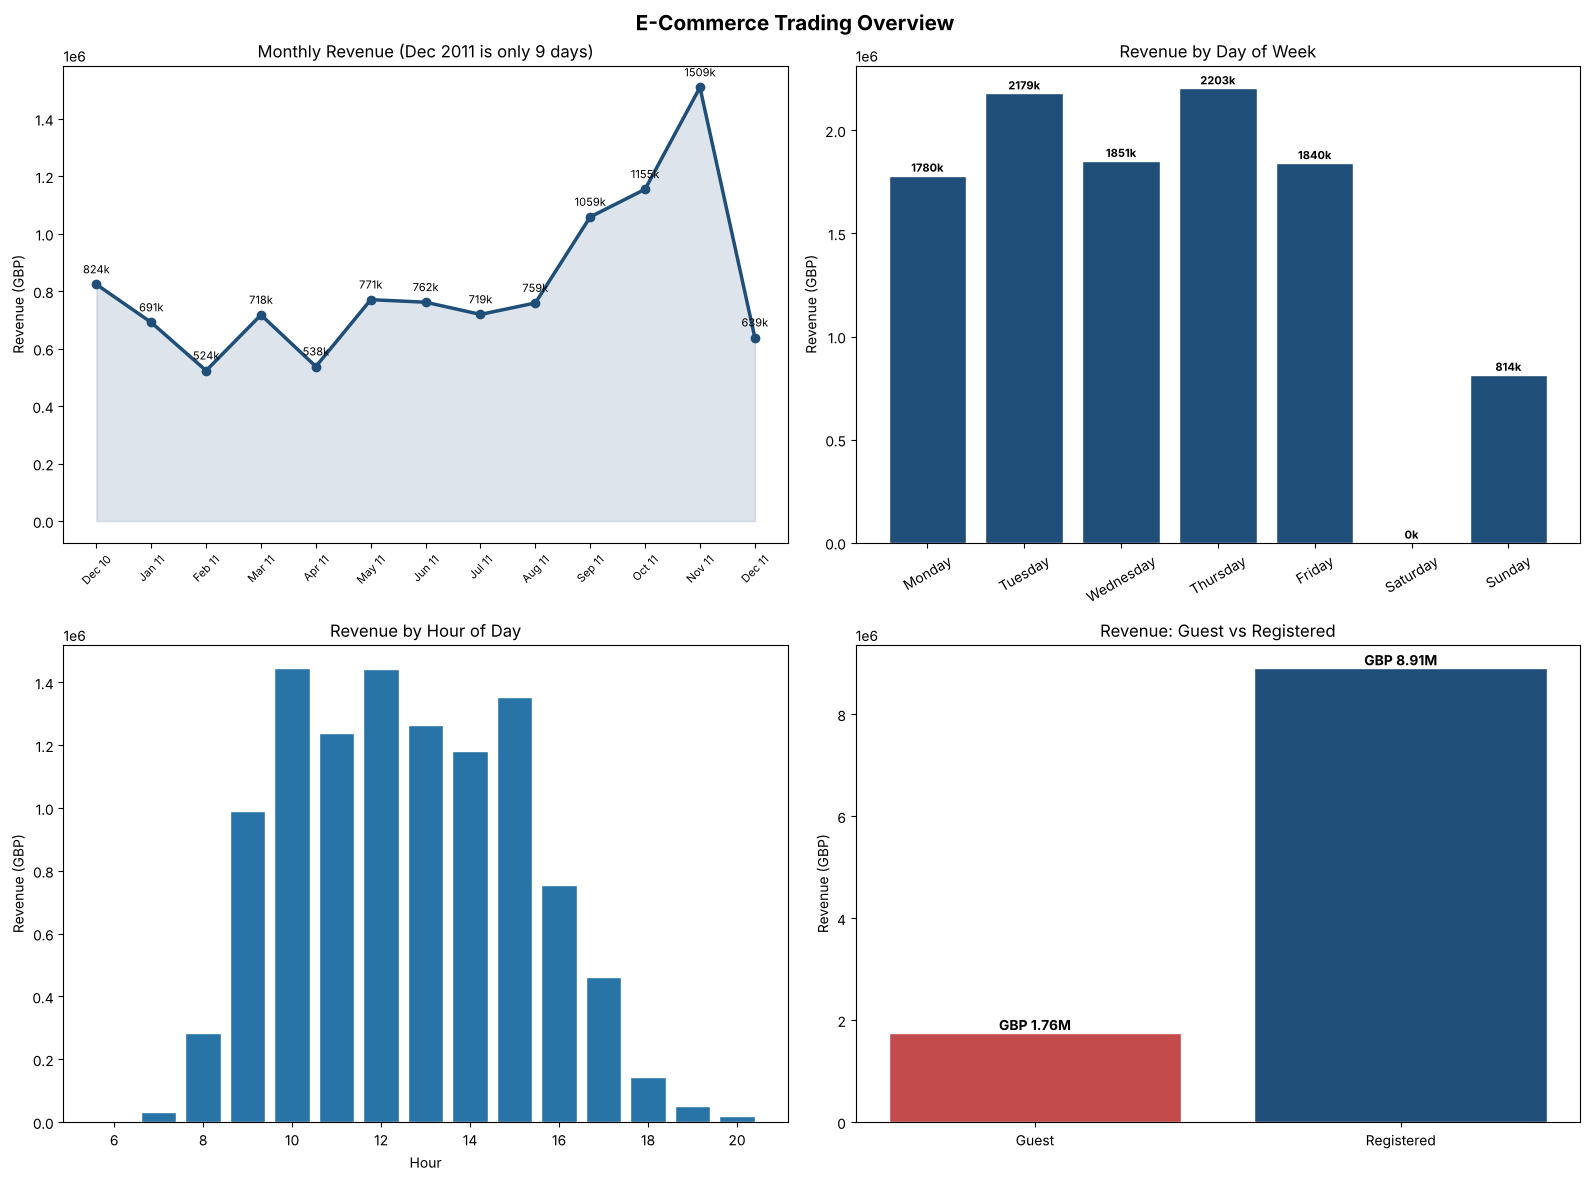

DayOfWeek
Monday       1779575.0
Tuesday      2178633.0
Wednesday    1851148.0
Thursday     2203161.0
Friday       1840340.0
Saturday           0.0
Sunday        813828.0
Name: Revenue, dtype: float64


In [3]:
# When does this business make its money?
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('E-Commerce Trading Overview', fontsize=15, fontweight='bold')

# Monthly revenue, by year-month so the two Decembers don't get merged
monthly = df.groupby('YearMonth')['Revenue'].sum()
labels = [p.strftime('%b %y') for p in monthly.index]
x = range(len(monthly))
axes[0, 0].plot(x, monthly.values, color='#1F4E79', linewidth=2.5, marker='o')
axes[0, 0].fill_between(x, monthly.values, alpha=0.15, color='#1F4E79')
axes[0, 0].set_xticks(list(x))
axes[0, 0].set_xticklabels(labels, rotation=45, fontsize=8)
axes[0, 0].set_title('Monthly Revenue (Dec 2011 is only 9 days)')
axes[0, 0].set_ylabel('Revenue (GBP)')
for i, v in zip(x, monthly.values):
    axes[0, 0].annotate(f'{v/1000:.0f}k', (i, v), textcoords='offset points',
                        xytext=(0, 8), ha='center', fontsize=8)

# Revenue by weekday. Saturday is kept in on purpose: it's zero.
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_revenue = df.groupby('DayOfWeek')['Revenue'].sum().reindex(day_order, fill_value=0)
axes[0, 1].bar(day_revenue.index, day_revenue.values, color='#1F4E79', edgecolor='white')
axes[0, 1].set_title('Revenue by Day of Week')
axes[0, 1].set_ylabel('Revenue (GBP)')
axes[0, 1].tick_params(axis='x', rotation=30)
for i, v in enumerate(day_revenue.values):
    axes[0, 1].text(i, v + 20000, f'{v/1000:.0f}k', ha='center', fontsize=8, fontweight='bold')

hourly = df.groupby('Hour')['Revenue'].sum()
axes[1, 0].bar(hourly.index, hourly.values, color='#2874A6', edgecolor='white')
axes[1, 0].set_title('Revenue by Hour of Day')
axes[1, 0].set_xlabel('Hour')
axes[1, 0].set_ylabel('Revenue (GBP)')

type_revenue = df.groupby('CustomerType')['Revenue'].sum()
axes[1, 1].bar(type_revenue.index, type_revenue.values,
               color=['#C44B4B', '#1F4E79'], edgecolor='white')
axes[1, 1].set_title('Revenue: Guest vs Registered')
axes[1, 1].set_ylabel('Revenue (GBP)')
for i, v in enumerate(type_revenue.values):
    axes[1, 1].text(i, v + 50000, f'GBP {v/1e6:.2f}M', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('images/1_trading_overview.png', dpi=150, bbox_inches='tight')
plt.show()

print(day_revenue.round(0))

## Key Finding 1: When this business makes its money

Revenue is fairly flat at GBP 0.5 to 0.8 million a month for most of the year. Then it climbs from September and peaks at GBP 1.51 million in November 2011. That looks like Christmas stock being bought early. (December 2011 looks like a drop, but that's only nine days of data.)

The weekday chart has a gap I missed the first time: **there are no Saturday transactions at all.** Thursday is the biggest day (GBP 2.20M). Sunday is the smallest of the six trading days, but at GBP 0.81M it isn't nothing. A shop that never trades on Saturday doesn't look like it sells to weekend shoppers. That fits the UCI description of the dataset, which says many of the company's customers are wholesalers.

Registered customers bring in about 84% of revenue, and guests the other 16% (GBP 1.76M).

                Total_Revenue  Orders  Avg_Order_Value  Median_Order_Value  AOV_vs_UK
Country                                                                              
United Kingdom      9025222.1   18019            500.9               300.5        1.0
Netherlands          285446.3      94           3036.7               806.9        6.1
EIRE                 283454.0     288            984.2               651.7        2.0
Germany              228867.1     457            500.8               356.1        1.0
France               209715.1     392            535.0               375.1        1.1
Australia            138521.3      57           2430.2               429.6        4.9
Spain                 61577.1      90            684.2               431.9        1.4
Switzerland           57089.9      54           1057.2               626.0        2.1
Belgium               41196.3      98            420.4               346.4        0.8
Sweden                38378.3      36           1066.1

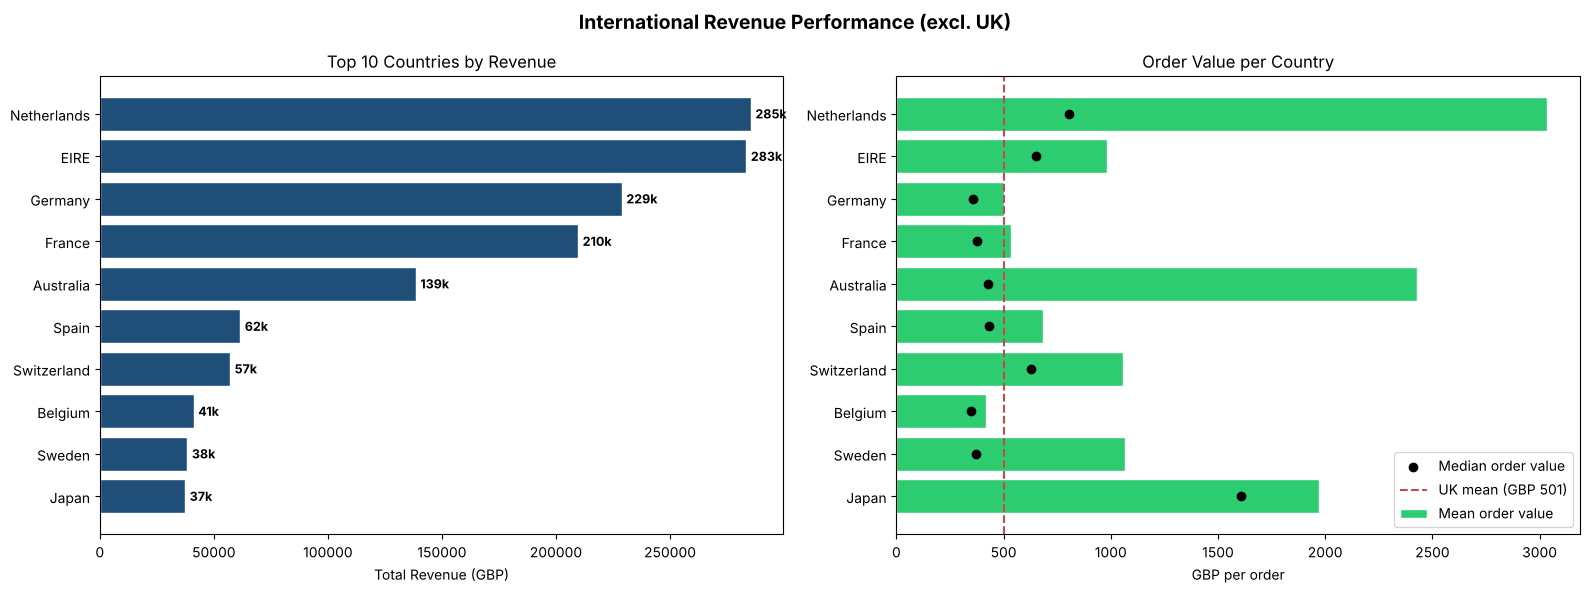

In [4]:
# Country performance, measured per ORDER.
# In the first version I took the mean of the Revenue column, which is the
# average value of one line on an invoice, and called it average order value.
# That was wrong. Here I add up each invoice first, then average.

orders = (df.groupby('InvoiceNo')
            .agg(OrderValue=('Revenue', 'sum'),
                 Lines=('Revenue', 'size'),
                 Country=('Country', 'first'),
                 CustomerType=('CustomerType', 'first'),
                 InvoiceDate=('InvoiceDate', 'first'))
            .reset_index())

country_stats = (orders.groupby('Country')
                   .agg(Total_Revenue=('OrderValue', 'sum'),
                        Orders=('OrderValue', 'size'),
                        Avg_Order_Value=('OrderValue', 'mean'),
                        Median_Order_Value=('OrderValue', 'median'))
                   .sort_values('Total_Revenue', ascending=False))

uk_aov = country_stats.loc['United Kingdom', 'Avg_Order_Value']
country_stats['AOV_vs_UK'] = country_stats['Avg_Order_Value'] / uk_aov

print(country_stats.head(12).round(1).to_string())

top = country_stats.drop('United Kingdom').head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('International Revenue Performance (excl. UK)', fontsize=14, fontweight='bold')

axes[0].barh(top.index[::-1], top['Total_Revenue'][::-1], color='#1F4E79', edgecolor='white')
axes[0].set_title('Top 10 Countries by Revenue')
axes[0].set_xlabel('Total Revenue (GBP)')
for i, v in enumerate(top['Total_Revenue'][::-1]):
    axes[0].text(v + 2000, i, f'{v/1000:.0f}k', va='center', fontweight='bold', fontsize=9)

axes[1].barh(top.index[::-1], top['Avg_Order_Value'][::-1], color='#2ecc71',
             edgecolor='white', label='Mean order value')
axes[1].scatter(top['Median_Order_Value'][::-1], range(len(top)), color='black',
                zorder=3, label='Median order value')
axes[1].axvline(uk_aov, color='#C44B4B', linestyle='--', label=f'UK mean (GBP {uk_aov:.0f})')
axes[1].set_title('Order Value per Country')
axes[1].set_xlabel('GBP per order')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('images/2_international_performance.png', dpi=150, bbox_inches='tight')
plt.show()

## Key Finding 2: A few countries place very large orders

In the first version I wrote that the Netherlands had an average order value of GBP 121 against GBP 18 for the UK. Those were averages per line item, not per order. Here are the real per-order numbers:

| Country | Orders | Mean order | Median order |
|---|---|---|---|
| United Kingdom | 18,019 | GBP 501 | GBP 301 |
| Netherlands | 94 | GBP 3,037 | GBP 807 |
| Australia | 57 | GBP 2,430 | GBP 430 |
| Japan | 19 | GBP 1,969 | GBP 1,607 |
| EIRE | 288 | GBP 984 | GBP 652 |

The Netherlands still comes out about six times the UK on the mean. But the median is far lower than the mean, so a handful of very large orders are doing most of the work. Australia is the same story. Japan is the only one where the typical order is large too, and that's based on just 19 orders.

EIRE is the one I find most useful. It has 288 orders, a steady median around GBP 650 and the second-highest revenue after the UK. Germany and France look a lot like the UK per order.

What I'd take from this: the high-value countries are a small number of big accounts. They're worth a phone call from sales, not a marketing campaign. With 19 to 94 orders each, I wouldn't build a market strategy on them.

TOP 10 PRODUCTS BY REVENUE
                                    Total_Revenue  Units_Sold  Times_Ordered
Description                                                                 
DOTCOM POSTAGE                          206248.77         706            706
REGENCY CAKESTAND 3 TIER                174484.74       13879           1988
PAPER CRAFT , LITTLE BIRDIE             168469.60       80995              1
WHITE HANGING HEART T-LIGHT HOLDER      106292.77       37891           2256
PARTY BUNTING                            99504.33       18295           1685
JUMBO BAG RED RETROSPOT                  94340.05       48474           2089
MEDIUM CERAMIC TOP STORAGE JAR           81700.92       78033            247
Manual                                   78112.82        7225            290
POSTAGE                                  78101.88        3150           1126
RABBIT NIGHT LIGHT                       66964.99       30788            994

TOP 10 PRODUCTS BY UNITS SOLD
                  

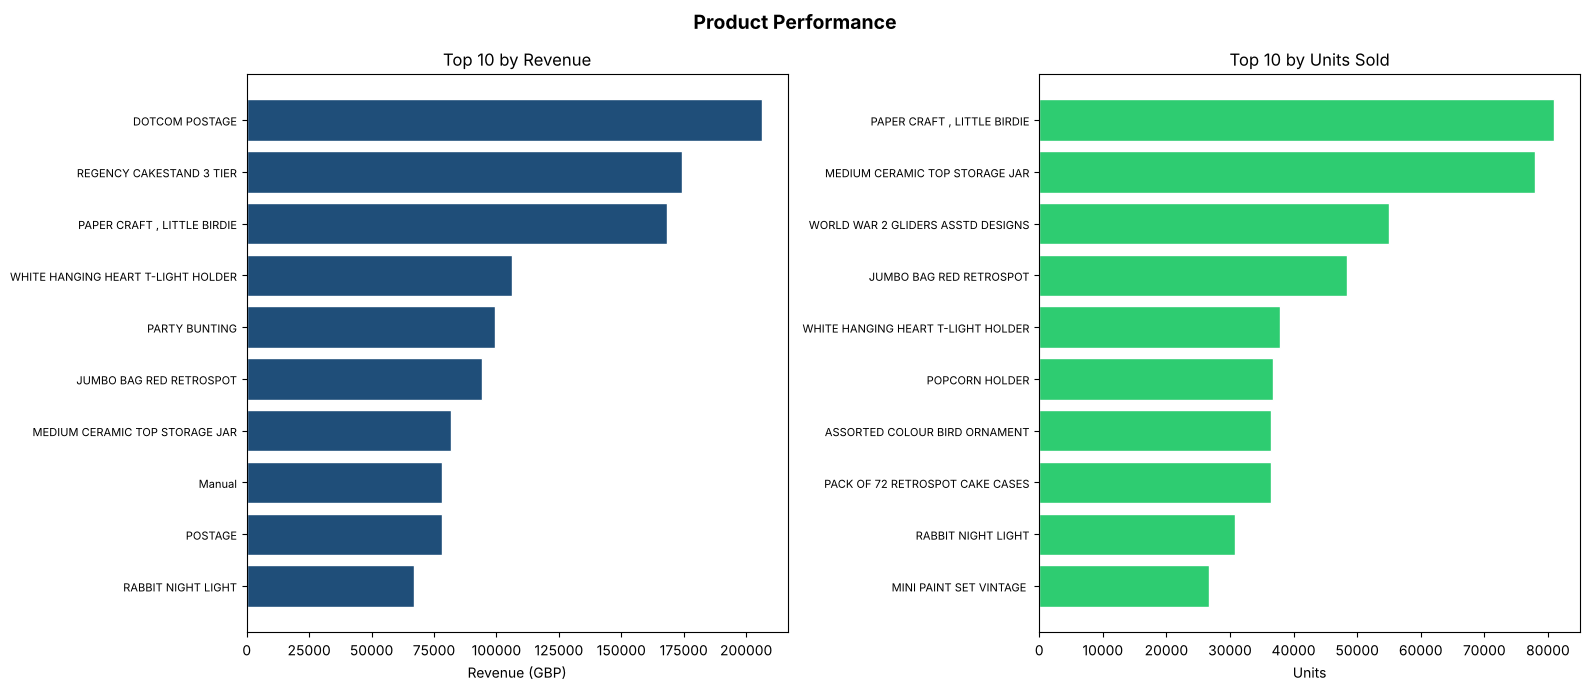

In [5]:
# Best sellers by revenue vs by units. These are often different lists.
product_stats = (df.groupby('Description')
                   .agg(Total_Revenue=('Revenue', 'sum'),
                        Units_Sold=('Quantity', 'sum'),
                        Times_Ordered=('InvoiceNo', 'nunique'))
                   .sort_values('Total_Revenue', ascending=False))

print("TOP 10 PRODUCTS BY REVENUE")
print(product_stats.head(10).to_string())
print("\nTOP 10 PRODUCTS BY UNITS SOLD")
print(product_stats.sort_values('Units_Sold', ascending=False).head(10).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Product Performance', fontsize=14, fontweight='bold')

by_rev = product_stats.head(10)
axes[0].barh(by_rev.index[::-1], by_rev['Total_Revenue'][::-1], color='#1F4E79', edgecolor='white')
axes[0].set_title('Top 10 by Revenue')
axes[0].set_xlabel('Revenue (GBP)')
axes[0].tick_params(axis='y', labelsize=8)

by_units = product_stats.sort_values('Units_Sold', ascending=False).head(10)
axes[1].barh(by_units.index[::-1], by_units['Units_Sold'][::-1], color='#2ecc71', edgecolor='white')
axes[1].set_title('Top 10 by Units Sold')
axes[1].set_xlabel('Units')
axes[1].tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.savefig('images/3_product_performance.png', dpi=150, bbox_inches='tight')
plt.show()

## A note on data quality

Before drawing any product conclusions I noticed a few things that would have quietly spoiled the analysis.

PAPER CRAFT, LITTLE BIRDIE shows 80,995 units sold in exactly one transaction. That's one enormous order, not a popular product. When I went looking, I found it was cancelled the same day (invoice C581484). The same thing happened with 74,215 MEDIUM CERAMIC TOP STORAGE JARs in January (C541433). Because I remove cancellation rows but keep the original sale, about GBP 246k of revenue in my totals never really happened. It's only about 2% of the total, so I've left it in to keep the numbers comparable with the first version. A proper fix would match each cancellation to its original sale and remove both.

DOTCOM POSTAGE and POSTAGE are shipping charges entered as product lines. They push up revenue totals and shouldn't be in a product ranking. DOTCOM POSTAGE turned out to be useful for something else, though, which comes up in section 4.

## Key Finding 3: Revenue rankings and volume rankings tell different stories

Ignoring postage, the REGENCY CAKESTAND 3 TIER is the strongest product by any sensible measure: GBP 174k across 1,988 separate orders. The WHITE HANGING HEART T-LIGHT HOLDER shows up in even more orders (2,256), so demand for it is broad and steady.

Any product dashboard for a business like this should leave out postage, manual adjustments and one-off bulk orders. Otherwise merchandising decisions end up being made on the back of a shipping fee.

## 4. Registered vs guest customers, and where my first answer went wrong

Two things to be upfront about.

**This isn't an A/B test.** Nobody was randomly told to register or check out as a guest. People (or businesses) chose, so any gap is a comparison between two groups that are different in lots of ways. The first version called it an A/B test, and that was the wrong name.

**"Guest" is my label, not the data's.** The data only shows that CustomerID is empty.

Here is the original comparison, per line item:

In [6]:
# The original version: one row = one line on an invoice
reg_lines = df.loc[df['CustomerType'] == 'Registered', 'Revenue']
guest_lines = df.loc[df['CustomerType'] == 'Guest', 'Revenue']

print("PER LINE ITEM (original version)")
print(f"Registered: n={len(reg_lines):,}  mean=GBP {reg_lines.mean():.2f}  median=GBP {reg_lines.median():.2f}")
print(f"Guest:      n={len(guest_lines):,}  mean=GBP {guest_lines.mean():.2f}  median=GBP {guest_lines.median():.2f}")
print(f"Registered mean is {reg_lines.mean() / guest_lines.mean() - 1:.0%} higher per line")

PER LINE ITEM (original version)
Registered: n=397,884  mean=GBP 22.40  median=GBP 11.80
Guest:      n=132,220  mean=GBP 13.28  median=GBP 4.96
Registered mean is 69% higher per line


That's where the 69% came from. The trouble is that a line item isn't a purchase. An order with 90 cheap lines and an order with 5 expensive lines count very differently here. The question a business actually cares about is how much someone spends **per order**, so I added up each invoice and compared again.

In [7]:
# The corrected version: one row = one order
reg_orders = orders.loc[orders['CustomerType'] == 'Registered', 'OrderValue']
guest_orders = orders.loc[orders['CustomerType'] == 'Guest', 'OrderValue']

print("PER ORDER (corrected)")
print(f"Registered: n={len(reg_orders):,}  mean=GBP {reg_orders.mean():.0f}  median=GBP {reg_orders.median():.0f}")
print(f"Guest:      n={len(guest_orders):,}  mean=GBP {guest_orders.mean():.0f}  median=GBP {guest_orders.median():.0f}")

# Order values are very skewed and the groups have very different spreads,
# so: Welch's t-test (doesn't assume equal variance), Mann-Whitney as a check
# that doesn't depend on the mean, and a bootstrap interval for the gap in GBP.
welch = stats.ttest_ind(guest_orders, reg_orders, equal_var=False)
mw = stats.mannwhitneyu(guest_orders, reg_orders)

rng = np.random.default_rng(42)
boot = [rng.choice(guest_orders.values, len(guest_orders)).mean()
        - rng.choice(reg_orders.values, len(reg_orders)).mean()
        for _ in range(2000)]
low, high = np.percentile(boot, [2.5, 97.5])

print(f"\nGuest minus registered, mean per order: GBP {guest_orders.mean() - reg_orders.mean():.0f}")
print(f"95% bootstrap interval: GBP {low:.0f} to GBP {high:.0f}")
print(f"Welch t-test p = {welch.pvalue:.1e}")
print(f"Mann-Whitney p = {mw.pvalue:.1e}")

PER ORDER (corrected)
Registered: n=18,532  mean=GBP 481  median=GBP 303
Guest:      n=1,428  mean=GBP 1229  median=GBP 465



Guest minus registered, mean per order: GBP 748
95% bootstrap interval: GBP 615 to GBP 899
Welch t-test p = 2.6e-24
Mann-Whitney p = 6.2e-05


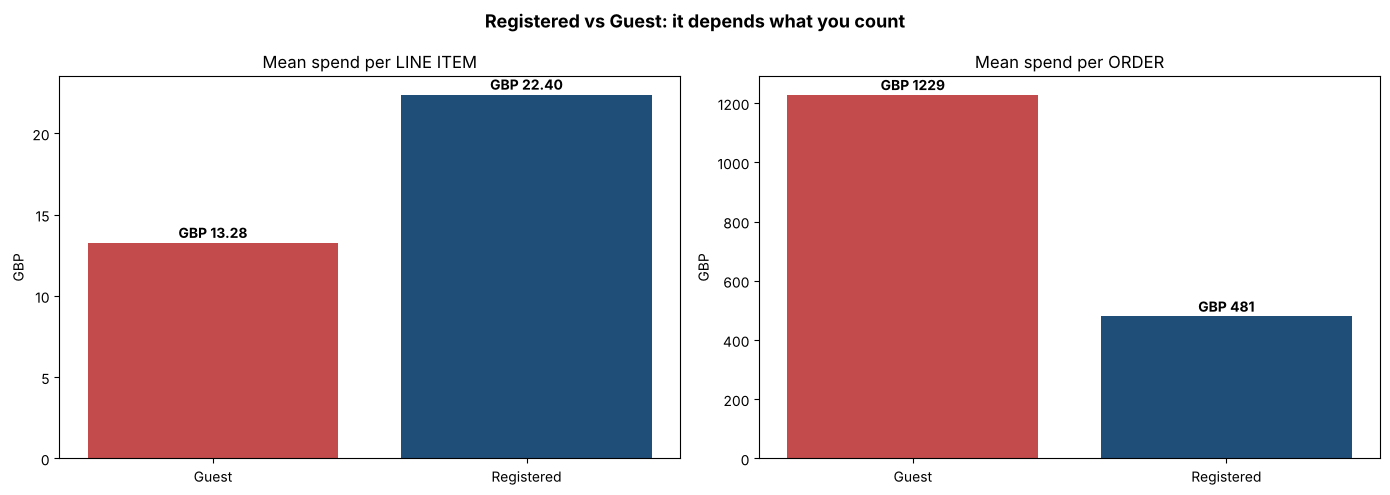

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Registered vs Guest: it depends what you count', fontsize=13, fontweight='bold')

compare = pd.DataFrame({
    'Per line item': [guest_lines.mean(), reg_lines.mean()],
    'Per order': [guest_orders.mean(), reg_orders.mean()],
}, index=['Guest', 'Registered'])

axes[0].bar(['Guest', 'Registered'], compare['Per line item'], color=['#C44B4B', '#1F4E79'])
axes[0].set_title('Mean spend per LINE ITEM')
axes[0].set_ylabel('GBP')
for i, v in enumerate(compare['Per line item']):
    axes[0].text(i, v + 0.3, f'GBP {v:.2f}', ha='center', fontweight='bold')

axes[1].bar(['Guest', 'Registered'], compare['Per order'], color=['#C44B4B', '#1F4E79'])
axes[1].set_title('Mean spend per ORDER')
axes[1].set_ylabel('GBP')
for i, v in enumerate(compare['Per order']):
    axes[1].text(i, v + 15, f'GBP {v:.0f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('images/4_registered_vs_guest.png', dpi=150, bbox_inches='tight')
plt.show()

Per order, the result flips. Guest orders average about GBP 1,229 against GBP 481 for registered ones. The 95% interval for the gap is roughly GBP 615 to GBP 900, and the medians point the same way (GBP 465 vs GBP 303). So the 69% headline was a side effect of counting line items. It wasn't a real difference in how much people spend.

That raised an obvious question: why would guest orders be bigger? So I looked at what's inside them.

In [9]:
# What do the two kinds of order actually look like?
profile = df.groupby('CustomerType').agg(
    median_qty_per_line=('Quantity', 'median'),
    median_unit_price=('UnitPrice', 'median'),
)
profile['median_lines_per_order'] = orders.groupby('CustomerType')['Lines'].median()
profile['orders'] = orders.groupby('CustomerType').size()

# DOTCOM POSTAGE is the website shipping charge, so it's a decent marker for web orders
dotcom_orders = df.loc[df['Description'] == 'DOTCOM POSTAGE', 'InvoiceNo'].unique()
orders['HasDotcomPostage'] = orders['InvoiceNo'].isin(dotcom_orders)
profile['share_with_dotcom_postage'] = orders.groupby('CustomerType')['HasDotcomPostage'].mean()

print(profile.round(2).T.to_string())

CustomerType                 Guest  Registered
median_qty_per_line           1.00        6.00
median_unit_price             3.29        1.95
median_lines_per_order       36.00       15.00
orders                     1428.00    18532.00
share_with_dotcom_postage     0.48        0.00


This is the part I find most interesting. The two groups look like two different kinds of buyer:

- **Registered orders** typically have about 15 lines, **6 units per line** and a median unit price of GBP 1.95. That's someone stocking a shop: a few products, bought in multiples.
- **Guest orders** typically have about 36 lines, **1 unit per line** and a median unit price of GBP 3.29. Almost half of them (690 of 1,428) carry a DOTCOM POSTAGE charge. Only 16 registered orders do.

So "guest" here mostly means **the website channel**, and "registered" mostly means **trade accounts**. Some guest invoices have hundreds or even over a thousand single-unit lines. My guess is that several web orders were sometimes booked under one invoice number. I can't prove that from this data, but it would explain why guest "orders" look so big.

**What this changes:** I can't say that getting guests to register would raise their spend. The two groups aren't the same people at different stages; they're different channels. The more useful recommendation is about data capture. GBP 1.76 million of web revenue (16% of the total) can't be linked to a customer, so you can't measure repeat purchases, lifetime value or retention for that channel. Fixing how web orders are recorded is the first step, before anyone runs a real experiment on registration prompts.

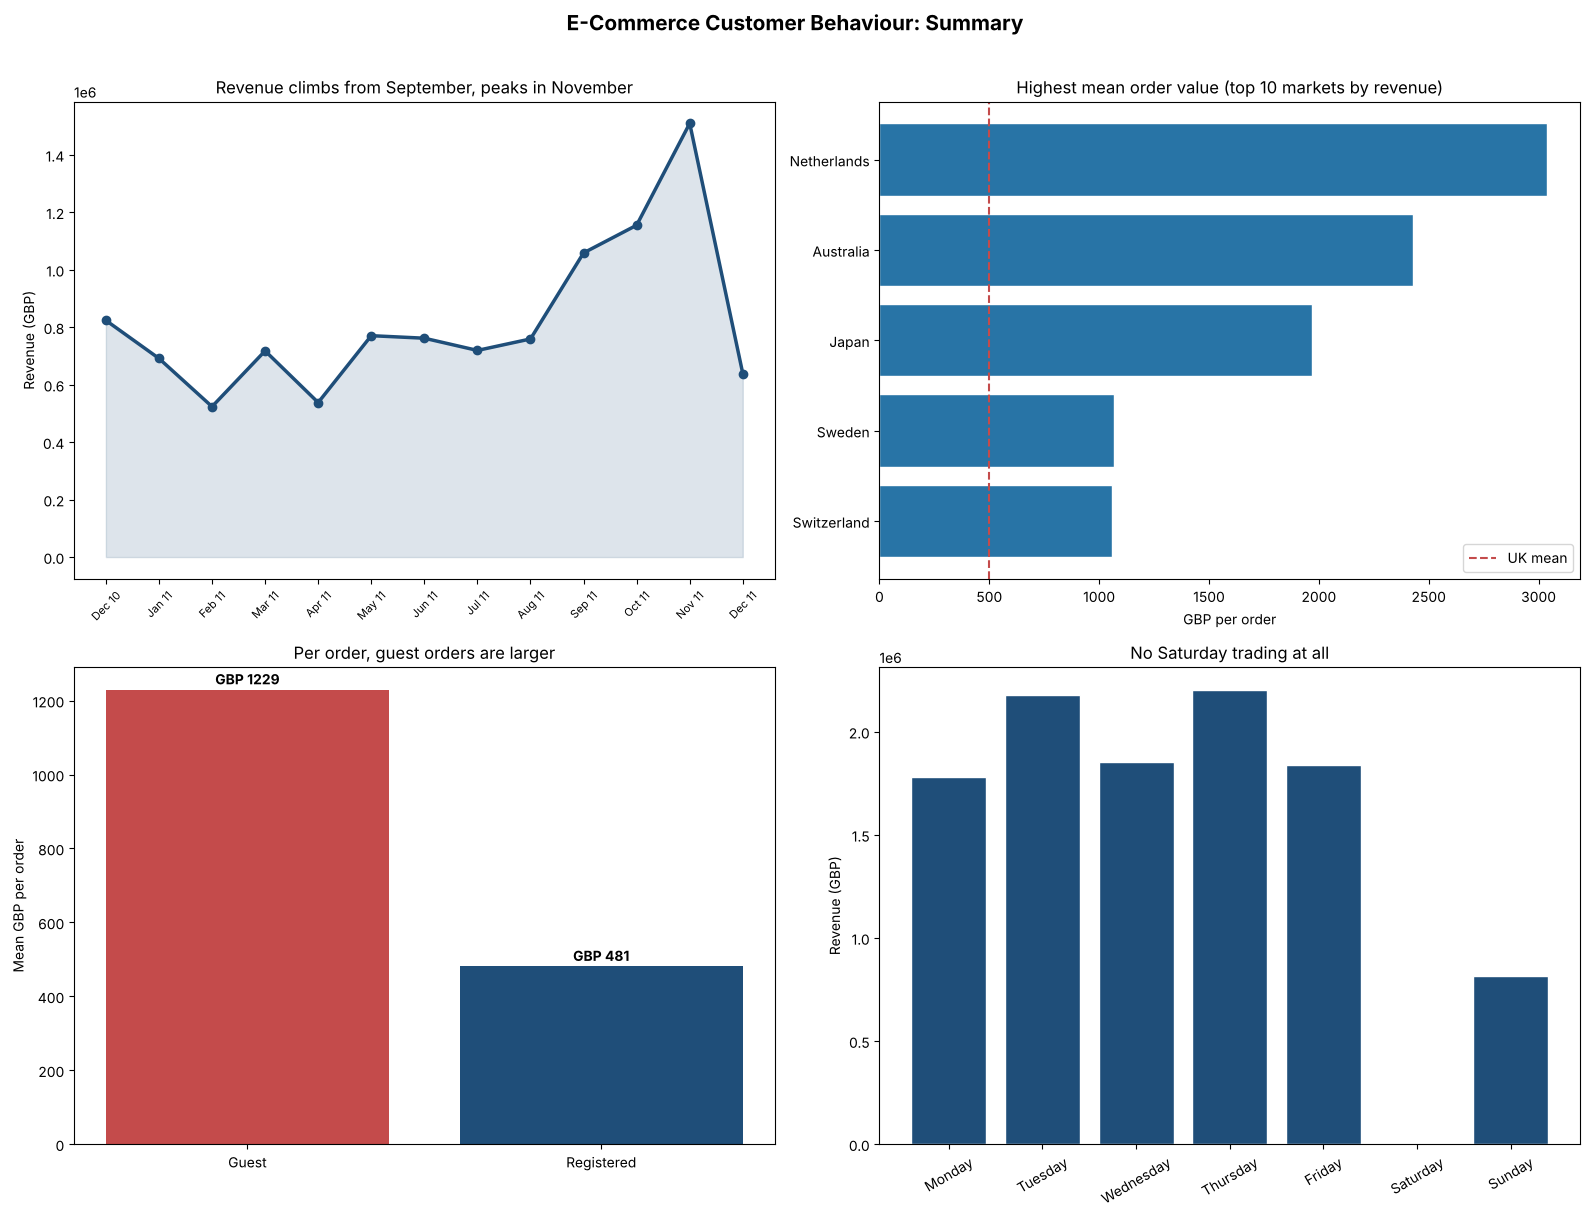

In [10]:
# One summary view with the corrected numbers
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('E-Commerce Customer Behaviour: Summary', fontsize=15, fontweight='bold', y=1.01)

axes[0, 0].plot(x, monthly.values, color='#1F4E79', linewidth=2.5, marker='o')
axes[0, 0].fill_between(x, monthly.values, alpha=0.15, color='#1F4E79')
axes[0, 0].set_xticks(list(x))
axes[0, 0].set_xticklabels(labels, rotation=45, fontsize=8)
axes[0, 0].set_title('Revenue climbs from September, peaks in November')
axes[0, 0].set_ylabel('Revenue (GBP)')

top5 = country_stats.drop('United Kingdom').head(10).sort_values('Avg_Order_Value').tail(5)
axes[0, 1].barh(top5.index, top5['Avg_Order_Value'], color='#2874A6', edgecolor='white')
axes[0, 1].axvline(uk_aov, color='#C44B4B', linestyle='--', label='UK mean')
axes[0, 1].set_title('Highest mean order value (top 10 markets by revenue)')
axes[0, 1].set_xlabel('GBP per order')
axes[0, 1].legend()

axes[1, 0].bar(['Guest', 'Registered'], compare['Per order'], color=['#C44B4B', '#1F4E79'])
axes[1, 0].set_title('Per order, guest orders are larger')
axes[1, 0].set_ylabel('Mean GBP per order')
for i, v in enumerate(compare['Per order']):
    axes[1, 0].text(i, v + 15, f'GBP {v:.0f}', ha='center', fontweight='bold')

axes[1, 1].bar(day_revenue.index, day_revenue.values, color='#1F4E79', edgecolor='white')
axes[1, 1].set_title('No Saturday trading at all')
axes[1, 1].set_ylabel('Revenue (GBP)')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('images/5_summary.png', dpi=150, bbox_inches='tight')
plt.show()

## Conclusions

**Revenue is seasonal.** Flat for most of the year, then a climb from September to a November peak of GBP 1.51M. Stock, staffing and campaigns should be planned around that autumn ramp, not December.

**The customer base splits into two kinds of buyer.** Registered accounts buy in multiples and look like trade customers. Orders with no customer ID look like website orders: single units, higher unit prices, website postage. Per line item registered customers seem to spend more. Per order it's the other way round. My first version of this project got this wrong because it counted line items.

**A handful of foreign accounts place very large orders.** The Netherlands, Australia and Japan have mean order values four to six times the UK's, but on 19 to 94 orders, and mostly driven by a few big invoices. EIRE is the steadiest international market.

**The biggest practical fix is data capture.** 16% of revenue has no customer attached. Until web orders are linked to customers, nobody can measure retention or lifetime value for that channel, or properly test whether registration prompts work.

## What I'd do next

- Separate the two channels properly and run an RFM or cohort analysis on registered customers only.
- Check whether the very large guest invoices are batches of web orders, maybe by looking at time stamps and order patterns.
- If I had access to the business, design a real randomised test of a post-purchase registration prompt. The data here can't tell us whether registering changes behaviour.